# 鸢尾花 PCA 降维：源码复现、逐段注释与工具函数学习笔记

本 Notebook 根据原始文件 `pca降维.ipynb` 整理，完成以下任务：

1. 跑通原源码中的“实践 1：鸢尾花降维”，并对数据处理、协方差矩阵、特征分解、降维、重构和可视化逐段注释；
2. 研究源码使用的 NumPy、scikit-learn、Matplotlib、Seaborn 与 OpenCV 工具函数，给出可运行范例；
3. 保留原源码第二部分“图像 PCA 降维”的思想，修正其中容易混淆或已弃用的写法，并给出可复现实验；
4. 使用 scikit-learn 的 `PCA` 对同一数据做交叉验证，确认手写 PCA 的结果。

> **提交对应关系**：(1)(2) 均在本 Notebook 中；(3) 为同仓库的 `index.html`。

## 0. 原源码结构速览

原文件包含两段 PCA 实践：

| 部分 | 输入 | 目标 | 核心步骤 |
|---|---|---|---|
| 鸢尾花降维 | 150 个样本 × 4 个特征 | 降到 2 维并可视化 | 去均值 → 协方差矩阵 → 特征分解 → 取前 k 个特征向量 → 投影 |
| 图像降维 | 灰度图像，每个像素列被视为一个特征 | 保留一定比例信息并重构图像 | 去均值 → 协方差矩阵 → 根据累计方差确定 k → 投影 → 重构 |

本题重点研究第一段，同时解释第二段中出现的工具函数和矩阵乘法易错点。

## 1. 环境准备

下面的代码固定随机种子并设置中文绘图字体。若在自己的电脑运行，请先执行：

```bash
pip install numpy pandas matplotlib seaborn scikit-learn opencv-python jupyterlab
```

In [1]:
import os
import warnings
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore', category=FutureWarning)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style='whitegrid', font='Microsoft YaHei')

print('NumPy:', np.__version__)
print('pandas:', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('OpenCV:', cv2.__version__)
print('运行目录:', Path.cwd())

NumPy: 2.4.1
pandas: 2.3.3
scikit-learn: 1.9.1
OpenCV: 5.1.0
运行目录: D:\人工智能原理\pca-iris-visualization


## 2. 鸢尾花数据加载与观察

`load_iris()` 返回字典式对象：

- `data`：`(150, 4)` 的特征矩阵；
- `target`：长度为 150 的类别编号；
- `feature_names`：4 个特征名称；
- `target_names`：3 个类别名称。

原源码只取 `data` 做无监督 PCA，没有使用标签参与降维；标签只用于最后的颜色区分。

In [2]:
iris = load_iris(as_frame=True)
X = iris.data.to_numpy(dtype=float)
y = iris.target.to_numpy(dtype=int)
feature_names = iris.feature_names
class_names = iris.target_names

print('特征矩阵形状:', X.shape)
print('类别数量:', len(class_names))
print('各类别样本数:', np.bincount(y).tolist())
display(iris.data.head())

summary = pd.DataFrame({
    '特征': feature_names,
    '均值': X.mean(axis=0),
    '标准差': X.std(axis=0, ddof=1),
    '最小值': X.min(axis=0),
    '最大值': X.max(axis=0),
})
display(summary.round(4))

特征矩阵形状: (150, 4)
类别数量: 3
各类别样本数: [50, 50, 50]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


,特征,均值,标准差,最小值,最大值
0,sepal length (cm),5.8433,0.8281,4.3,7.9
1,sepal width (cm),3.0573,0.4359,2.0,4.4
2,petal length (cm),3.7580,1.7653,1.0,6.9
3,petal width (cm),1.1993,0.7622,0.1,2.5


## 3. 手写 PCA：按原源码逻辑复现

为了保持与原始代码一致，这里仍使用 `np.linalg.eig` 对协方差矩阵做特征分解，并保留原类名 `PCAtest` 的方法划分。详细注释标在每一段关键代码旁。

> 注意：原源码中的“标准化”只执行了**去均值**，没有除以标准差。因此本文把这个步骤称为“中心化（零均值化）”，以准确区分于 z-score 标准化。

In [3]:
class PCAtest:
    """手写 PCA，方法流程与原始源码一致。"""

    def __init__(self, k: int):
        # 目标维度 k：鸢尾花实验取 2，表示把 4 维特征压缩为 2 维。
        if not isinstance(k, int) or k <= 0:
            raise ValueError('k 必须是正整数')
        self.k = k

    def loadIris(self) -> np.ndarray:
        """只加载鸢尾花的数值特征，返回形状 (150, 4) 的数组。"""
        return load_iris()['data'].astype(float)

    def stand_data(self, data: np.ndarray):
        """零均值化：逐列求均值，再让每个样本减去该均值向量。"""
        mean_vector = np.mean(data, axis=0)
        centered_data = data - mean_vector
        return mean_vector, centered_data

    def getCovMat(self, centered_data: np.ndarray) -> np.ndarray:
        """计算特征之间的协方差矩阵。

        rowvar=0 表示每一列是一个变量（特征），每一行是一个样本。
        对 (150, 4) 数据，协方差矩阵形状是 (4, 4)。
        """
        return np.cov(centered_data, rowvar=0)

    def getFValueAndFVector(self, cov_mat: np.ndarray):
        """对协方差矩阵做特征分解：C v = λ v。

        fValue 是特征值，fVector 的每一列是对应特征向量。
        特征值越大，对应方向包含的数据方差越多。
        """
        f_value, f_vector = np.linalg.eig(cov_mat)
        # 协方差矩阵理论上是实对称矩阵，这里主动去掉数值计算产生的极小虚部。
        f_value = np.real_if_close(f_value, tol=1000).real
        f_vector = np.real_if_close(f_vector, tol=1000).real
        return f_value, f_vector

    def getVectorMatrix(self, f_value: np.ndarray, f_vector: np.ndarray) -> np.ndarray:
        """按特征值降序排序，取前 k 个特征向量组成投影矩阵。"""
        sorted_indices = np.argsort(-f_value)
        top_k_indices = sorted_indices[:self.k]
        return f_vector[:, top_k_indices]

    def getResult(self, centered_data: np.ndarray, vector_mat: np.ndarray) -> np.ndarray:
        """把中心化数据投影到前 k 个主成分方向。"""
        return np.dot(centered_data, vector_mat)

    def explained_variance_ratio(self, f_value: np.ndarray) -> np.ndarray:
        """返回各主成分解释的方差比例（附加方法，便于解释结果）。"""
        sorted_values = np.sort(f_value)[::-1]
        return sorted_values / sorted_values.sum()

    def reconstruct(self, projected: np.ndarray, vector_mat: np.ndarray,
                    mean_vector: np.ndarray) -> np.ndarray:
        """从 k 维主成分坐标恢复到原特征空间。

        投影矩阵 vector_mat 的形状为 (4, k)，所以使用 vector_mat.T。
        """
        return projected @ vector_mat.T + mean_vector


pca_manual = PCAtest(k=2)
X_manual = pca_manual.loadIris()
mean_vector, X_centered = pca_manual.stand_data(X_manual)
cov_matrix = pca_manual.getCovMat(X_centered)
eigenvalues, eigenvectors = pca_manual.getFValueAndFVector(cov_matrix)
projection_matrix = pca_manual.getVectorMatrix(eigenvalues, eigenvectors)
X_pca_manual = pca_manual.getResult(X_centered, projection_matrix)
X_reconstructed = pca_manual.reconstruct(X_pca_manual, projection_matrix, mean_vector)

print('原始数据形状:', X_manual.shape)
print('投影矩阵形状:', projection_matrix.shape)
print('降维后形状:', X_pca_manual.shape)
print('重构后形状:', X_reconstructed.shape)

原始数据形状: (150, 4)
投影矩阵形状: (4, 2)
降维后形状: (150, 2)
重构后形状: (150, 4)


### 3.1 验证零均值化与协方差矩阵

中心化后每一列的均值应接近 0；协方差矩阵应满足对称性。这两项检查能尽早发现“按行/按列处理错误”的问题。

In [4]:
centered_means = X_centered.mean(axis=0)
assert X_centered.shape == (150, 4)
assert np.allclose(centered_means, 0.0, atol=1e-12)
assert np.allclose(cov_matrix, cov_matrix.T)

centered_table = pd.DataFrame({
    '特征': feature_names,
    '中心化后的均值': centered_means,
})
display(centered_table.style.format({'中心化后的均值': '{:.3e}'}))

print('协方差矩阵:')
display(pd.DataFrame(cov_matrix, index=feature_names, columns=feature_names).round(4))

,特征,中心化后的均值
0,sepal length (cm),-1.125e-15
1,sepal width (cm),-7.609e-16
2,petal length (cm),-2.552e-15
3,petal width (cm),-4.485e-16


协方差矩阵:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
sepal length (cm),0.6857,-0.0424,1.2743,0.5163
sepal width (cm),-0.0424,0.1900,-0.3297,-0.1216
petal length (cm),1.2743,-0.3297,3.1163,1.2956
petal width (cm),0.5163,-0.1216,1.2956,0.5810


### 3.2 特征值、特征向量与解释方差

原源码使用 `argsort(-f_value)` 得到降序索引。主成分的解释方差比例为：

\[
\text{explained ratio}_i = \frac{\lambda_i}{\sum_j \lambda_j}
\]

两个主成分累计解释比例可由结果直接验证。

In [5]:
sorted_indices = np.argsort(-eigenvalues)
sorted_eigenvalues = eigenvalues[sorted_indices]
eigen_table = pd.DataFrame({
    '主成分': [f'PC{i + 1}' for i in range(4)],
    '特征值': sorted_eigenvalues,
    '解释方差比例': pca_manual.explained_variance_ratio(eigenvalues),
})
eigen_table['累计解释比例'] = eigen_table['解释方差比例'].cumsum()
display(eigen_table.style.format({
    '特征值': '{:.6f}',
    '解释方差比例': '{:.2%}',
    '累计解释比例': '{:.2%}',
}))

print('特征向量矩阵（每一列是一个主成分方向）:')
display(pd.DataFrame(
    eigenvectors,
    index=feature_names,
    columns=[f'PC{i + 1}' for i in range(4)]
).round(4))

variance_2d = eigen_table.loc[:1, '累计解释比例'].iloc[-1]
variance_3d = eigen_table.loc[:2, '累计解释比例'].iloc[-1]
print(f'前 2 个主成分累计解释方差: {variance_2d:.2%}')
print(f'前 3 个主成分累计解释方差: {variance_3d:.2%}')

,主成分,特征值,解释方差比例,累计解释比例
0,PC1,4.228242,92.46%,92.46%
1,PC2,0.242671,5.31%,97.77%
2,PC3,0.078210,1.71%,99.48%
3,PC4,0.023835,0.52%,100.00%


特征向量矩阵（每一列是一个主成分方向）:


,PC1,PC2,PC3,PC4
sepal length (cm),0.3614,-0.6566,-0.5820,0.3155
sepal width (cm),-0.0845,-0.7302,0.5979,-0.3197
petal length (cm),0.8567,0.1734,0.0762,-0.4798
petal width (cm),0.3583,0.0755,0.5458,0.7537


前 2 个主成分累计解释方差: 97.77%
前 3 个主成分累计解释方差: 99.48%


### 3.3 主成分方向与碎石图

- 碎石图用于判断保留多少个主成分；
- 特征向量绝对值越大，说明该主成分在该原始特征方向上的载荷越强；
- 特征向量的正负号可以整体翻转，因为相反方向仍表示同一条直线。

从鸢尾花结果可见，PC1 主要在花瓣长度、花瓣宽度和萼片长度上具有较大载荷，PC2 在萼片宽度方向更突出。

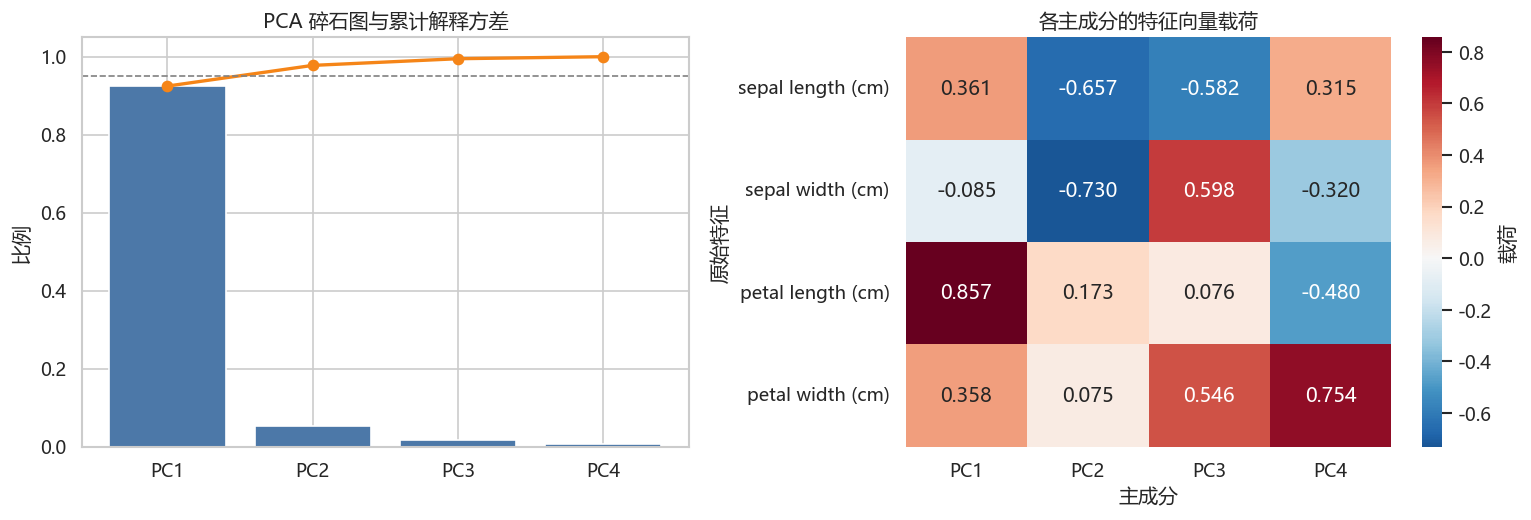

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(eigen_table['主成分'], eigen_table['解释方差比例'], color='#4C78A8')
axes[0].plot(eigen_table['主成分'], eigen_table['累计解释比例'],
             color='#F58518', marker='o', linewidth=2)
axes[0].axhline(0.95, color='gray', linestyle='--', linewidth=1)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('PCA 碎石图与累计解释方差')
axes[0].set_ylabel('比例')

sns.heatmap(
    pd.DataFrame(eigenvectors, index=feature_names,
                 columns=[f'PC{i + 1}' for i in range(4)]),
    annot=True, fmt='.3f', cmap='RdBu_r', center=0,
    ax=axes[1], cbar_kws={'label': '载荷'}
)
axes[1].set_title('各主成分的特征向量载荷')
axes[1].set_xlabel('主成分')
axes[1].set_ylabel('原始特征')

plt.tight_layout()
plt.show()

### 3.4 鸢尾花的二维 PCA 可视化

降维后的坐标不直接对应某一个原始特征，而是“主成分坐标”。下图中颜色表示真实鸢尾花类别，类别仅在可视化时使用，不参与 PCA 拟合。

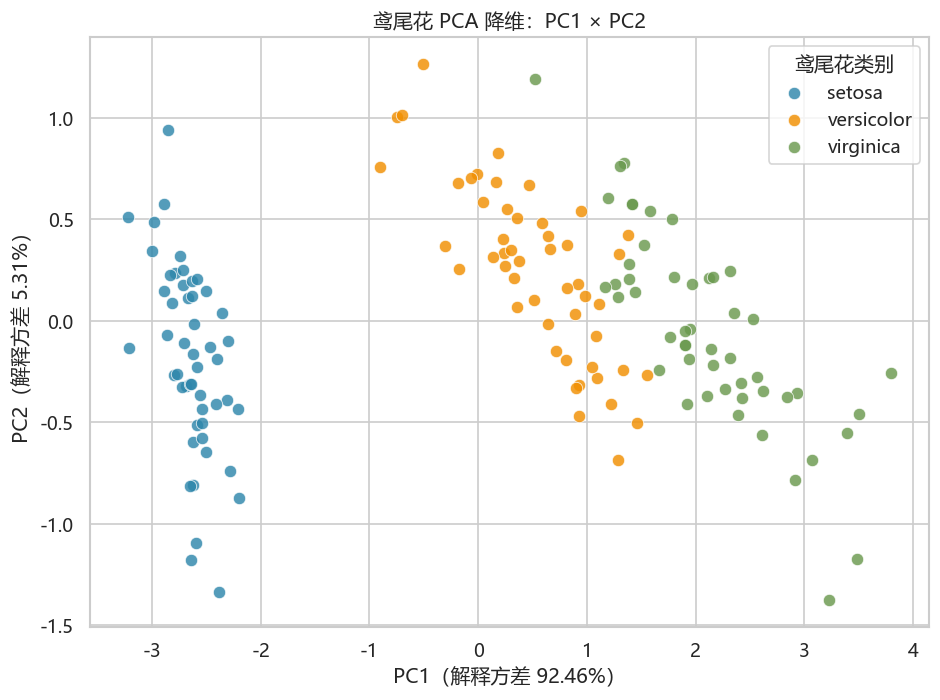

In [7]:
fig, ax = plt.subplots(figsize=(8, 6))
palette = ['#2E86AB', '#F18F01', '#6A994E']

for class_id, class_name in enumerate(class_names):
    mask = y == class_id
    ax.scatter(
        X_pca_manual[mask, 0], X_pca_manual[mask, 1],
        s=55, alpha=0.82, color=palette[class_id], label=class_name,
        edgecolor='white', linewidth=0.5
    )

ax.set_title('鸢尾花 PCA 降维：PC1 × PC2')
ax.set_xlabel(f'PC1（解释方差 {eigen_table.iloc[0, 2]:.2%}）')
ax.set_ylabel(f'PC2（解释方差 {eigen_table.iloc[1, 2]:.2%}）')
ax.legend(title='鸢尾花类别')
plt.tight_layout()
plt.show()

**观察结论**：二维平面上，Setosa 与其他两类基本分离；Versicolor 与 Virginica 仍有少量重叠。PCA 本身没有使用标签，但仍然保留了大量有利于分类的结构信息。

### 3.5 投影与重构：降维究竟损失了什么

若保留全部 4 个主成分，可在浮点误差范围内完整恢复原始数据。只保留 2 个主成分时，必然丢弃后两个方向上的信息：

\[
X \approx X_{\text{centered}} P P^T + \mu
\]

其中 \(P\) 是 `(4, 2)` 的投影矩阵。

In [8]:
mse_centered = np.mean((X_centered - (X_pca_manual @ projection_matrix.T)) ** 2)
mse_original = np.mean((X_manual - X_reconstructed) ** 2)
feature_mae = np.mean(np.abs(X_manual - X_reconstructed), axis=0)

print(f'2 维重构的均方误差（原数据尺度）: {mse_original:.6f}')
print(f'2 维重构的平均绝对误差: {np.mean(feature_mae):.6f}')

error_table = pd.DataFrame({
    '特征': feature_names,
    '平均绝对重构误差': feature_mae,
})
display(error_table.style.format({'平均绝对重构误差': '{:.4f}'}))

# 与 sklearn PCA 交叉验证。PCA 会自动做中心化，但不会自动缩放特征。
sklearn_pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_sklearn = sklearn_pca.fit_transform(X_manual)

print('手写版解释方差比例:', pca_manual.explained_variance_ratio(eigenvalues)[:2])
print('sklearn 解释方差比例:', sklearn_pca.explained_variance_ratio_)
print('两者数值一致:', np.allclose(
    pca_manual.explained_variance_ratio(eigenvalues)[:2],
    sklearn_pca.explained_variance_ratio_,
    atol=1e-10
))
# 主成分整体符号可以相反，因此比较确定主成分的绝对值。
print('主成分向量（按符号对齐后）一致:', np.allclose(
    np.abs(projection_matrix), np.abs(sklearn_pca.components_.T), atol=1e-10
))

2 维重构的均方误差（原数据尺度）: 0.025341
2 维重构的平均绝对误差: 0.121715


,特征,平均绝对重构误差
0,sepal length (cm),0.1377
1,sepal width (cm),0.1413
2,petal length (cm),0.0605
3,petal width (cm),0.1474


手写版解释方差比例: [0.92461872 0.05306648]
sklearn 解释方差比例: [0.92461872 0.05306648]
两者数值一致: True
主成分向量（按符号对齐后）一致: True


### 3.6 修正原源码可视化中的坐标含义

原源码 `show_picture(standdata, newdata)` 把：

- `standdata[:, :2]`：中心化后的原始前两个特征；
- `newdata[:, :2]`：PC1、PC2 坐标；

画在同一张坐标系中。两组坐标的语义和尺度不同，因此不应解释为“原始点与重构点重合度”。下面改为左右并列对比，并在 PCA 图中按类别着色。

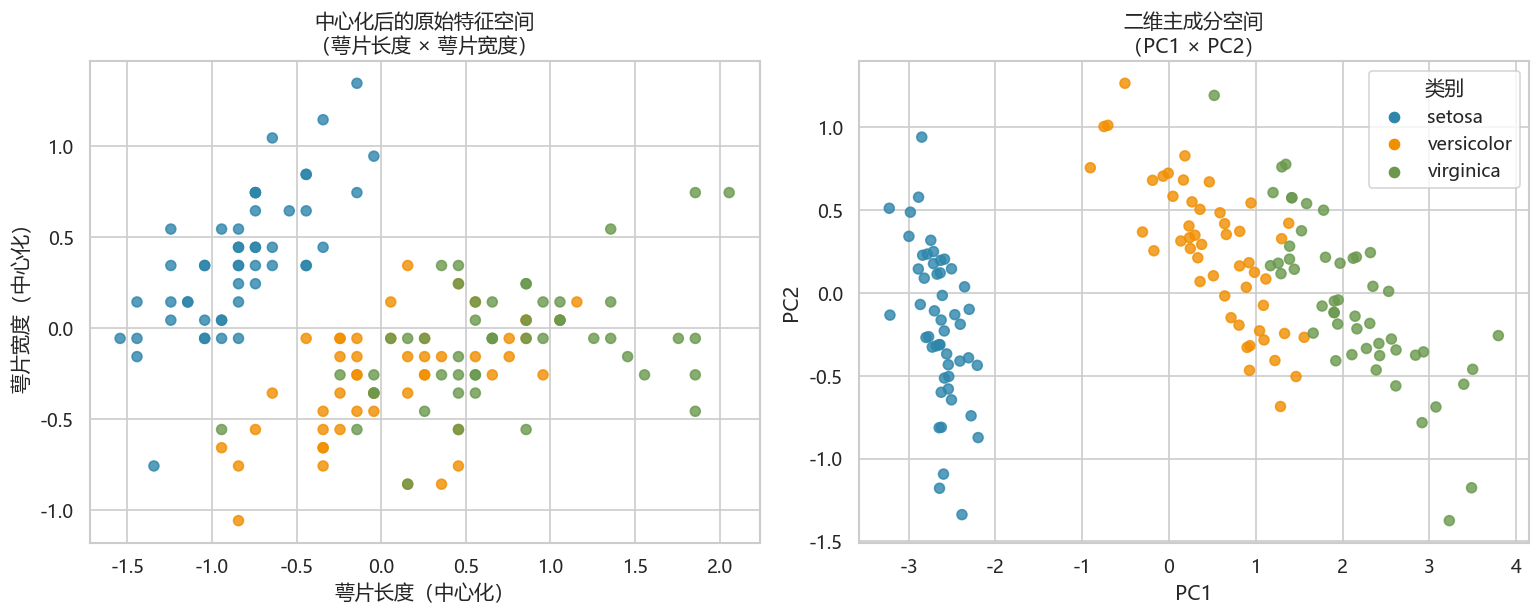

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.3), sharey=False)

axes[0].scatter(
    X_centered[:, 0], X_centered[:, 1],
    c=[palette[value] for value in y], s=35, alpha=0.8
)
axes[0].set_title('中心化后的原始特征空间\n（萼片长度 × 萼片宽度）')
axes[0].set_xlabel('萼片长度（中心化）')
axes[0].set_ylabel('萼片宽度（中心化）')

axes[1].scatter(
    X_pca_manual[:, 0], X_pca_manual[:, 1],
    c=[palette[value] for value in y], s=35, alpha=0.8
)
axes[1].set_title('二维主成分空间\n（PC1 × PC2）')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')

for class_id, class_name in enumerate(class_names):
    axes[1].scatter([], [], c=palette[class_id], label=class_name)
axes[1].legend(title='类别')

plt.tight_layout()
plt.show()

## 4. 原源码第二段：图像 PCA 的修正复现

原代码把灰度图像的每一列像素视为一个特征，把每一行视为一个样本。例如 `(300, 500)` 的灰度图可视为 300 个 500 维样本。根据累计解释方差自动确定 k 后，用前 k 个特征向量完成投影和重构。

为让实验无需依赖原作者的 `banana.jpg`，下面生成一张确定性的示例图，并真实保存、读取它，从而覆盖 `cv.imwrite`、`cv.imread`、`cv.cvtColor` 的用法。

保存文件: D:\人工智能原理\pca-iris-visualization\sample_image.png
BGR 数组形状: (360, 480, 3)
灰度数组形状: (360, 480)


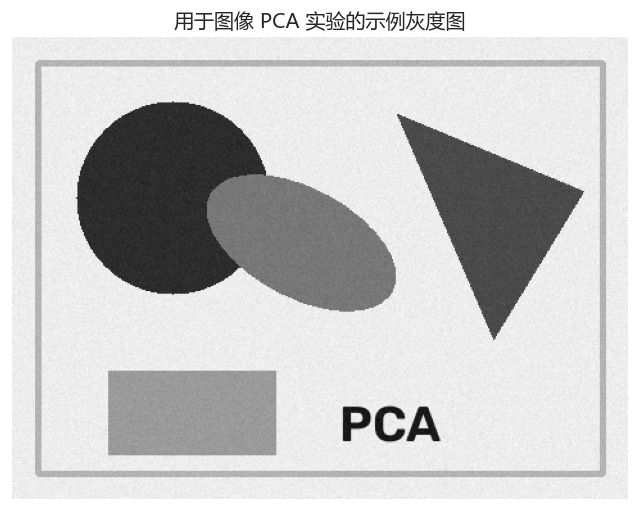

In [10]:
def create_demo_image(width: int = 480, height: int = 360) -> np.ndarray:
    """生成一张具有多种形状和灰度层次的示例图。"""
    canvas = np.full((height, width), 238, dtype=np.uint8)
    cv2.rectangle(canvas, (20, 20), (width - 20, height - 20), 180, 3)
    cv2.circle(canvas, (125, 125), 75, 45, -1)
    cv2.ellipse(canvas, (225, 160), (80, 42), 28, 0, 360, 120, -1)
    points = np.array([[300, 60], [445, 120], [375, 235]], dtype=np.int32)
    cv2.fillPoly(canvas, [points], 75)
    cv2.rectangle(canvas, (75, 260), (205, 325), 155, -1)
    cv2.putText(canvas, 'PCA', (255, 315), cv2.FONT_HERSHEY_SIMPLEX,
                1.35, 25, 3, cv2.LINE_AA)
    noise = np.random.default_rng(RANDOM_STATE).normal(0, 5, canvas.shape)
    return np.clip(canvas.astype(float) + noise, 0, 255).astype(np.uint8)


sample_path = Path('sample_image.png')
image_gray = create_demo_image()
cv2.imwrite(str(sample_path), image_gray)
loaded_bgr = cv2.imread(str(sample_path), cv2.IMREAD_COLOR)
loaded_gray = cv2.cvtColor(loaded_bgr, cv2.COLOR_BGR2GRAY)

print('保存文件:', sample_path.resolve())
print('BGR 数组形状:', loaded_bgr.shape)
print('灰度数组形状:', loaded_gray.shape)

fig, ax = plt.subplots(figsize=(7, 5))
ax.imshow(loaded_gray, cmap='gray', vmin=0, vmax=255)
ax.set_title('用于图像 PCA 实验的示例灰度图')
ax.axis('off')
plt.show()

In [11]:
def percentage_to_n(eigenvalues: np.ndarray, percentage: float) -> int:
    """按累计解释方差比例确定最少保留多少个主成分。"""
    if not 0 < percentage <= 1:
        raise ValueError('percentage 必须在 (0, 1] 内')
    sorted_values = np.sort(eigenvalues)[::-1]
    ratio = sorted_values / sorted_values.sum()
    return int(np.searchsorted(np.cumsum(ratio), percentage, side='left') + 1)


def pca_image(image: np.ndarray, percentage: float = 0.99) -> dict:
    """对灰度图做 PCA 降维和重构，返回完整中间结果。

    原源码只返回重构图像；这里额外返回投影数据、主成分数、特征值和
    解释方差比例，便于学习与检查。
    """
    data_matrix = np.asarray(image, dtype=np.float64)
    rows, cols = data_matrix.shape

    # 原函数 Z_centered：按列中心化；均值矩阵用于最后加回。
    mean_vector = data_matrix.mean(axis=0)
    centered = data_matrix - mean_vector

    # 图像每一列是特征，因此 rowvar=False。
    covariance = np.cov(centered, rowvar=False)

    # 协方差矩阵是实对称矩阵，eigh 更稳定，且特征值天然升序。
    eigenvalues, eigenvectors = np.linalg.eigh(covariance)
    sort_indices = np.argsort(eigenvalues)[::-1]
    eigenvalues = eigenvalues[sort_indices]
    eigenvectors = eigenvectors[:, sort_indices]

    k = percentage_to_n(eigenvalues, percentage)
    components = eigenvectors[:, :k]
    projected = centered @ components
    reconstructed = projected @ components.T + mean_vector

    ratio = eigenvalues / eigenvalues.sum()
    return {
        'original': data_matrix,
        'projected': projected,
        'reconstructed': reconstructed,
        'components': components,
        'eigenvalues': eigenvalues,
        'k': k,
        'rows': rows,
        'cols': cols,
        'ratio': ratio,
        'cumulative_ratio': np.cumsum(ratio),
    }


image_result_99 = pca_image(loaded_gray, percentage=0.99)
mse_image = np.mean((loaded_gray - image_result_99['reconstructed']) ** 2)

print(f"原始特征维度: {image_result_99['cols']}")
print(f"保留 99% 方差所需主成分数 k: {image_result_99['k']}")
print(f"实际累计解释比例: {image_result_99['cumulative_ratio'][image_result_99['k'] - 1]:.6%}")
print(f"图像重构均方误差: {mse_image:.4f}")

原始特征维度: 480
保留 99% 方差所需主成分数 k: 73
实际累计解释比例: 99.012065%
图像重构均方误差: 38.2013


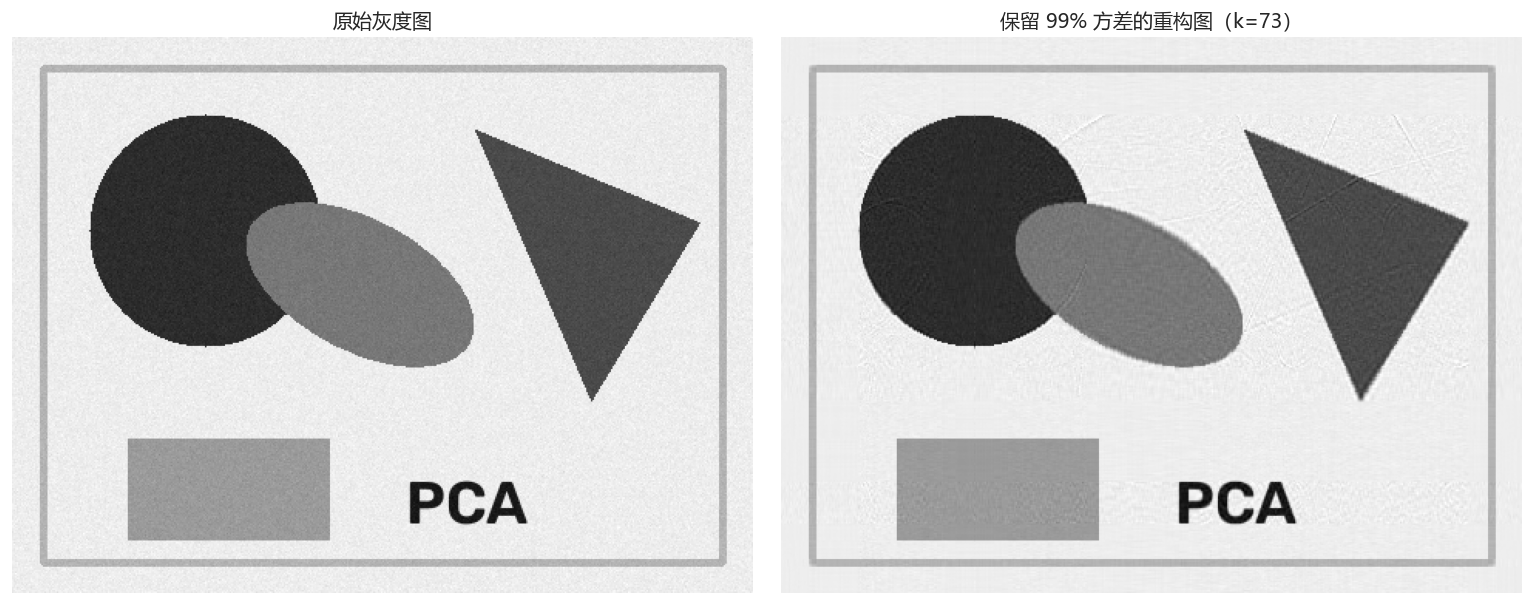

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(loaded_gray, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('原始灰度图')
axes[0].axis('off')

axes[1].imshow(np.clip(image_result_99['reconstructed'], 0, 255), cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"保留 99% 方差的重构图（k={image_result_99['k']}）")
axes[1].axis('off')
plt.tight_layout()
plt.show()

,保留比例目标,主成分数 k,实际累计比例,重构 MSE
0,80%,4,83.3592%,643.4632
1,90%,8,90.4493%,369.3030
2,95%,16,95.0106%,192.9277
3,99%,73,99.0121%,38.2013


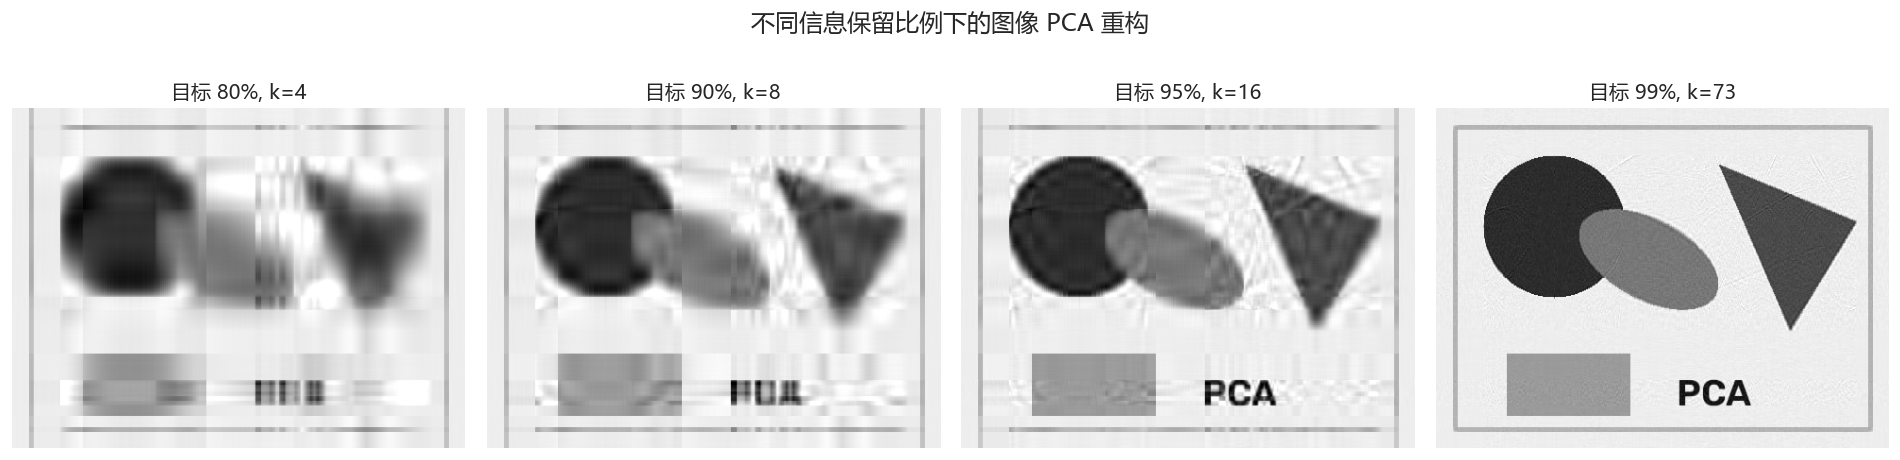

In [13]:
energies = [0.80, 0.90, 0.95, 0.99]
image_table = []
for energy in energies:
    result = pca_image(loaded_gray, percentage=energy)
    image_mse = np.mean((loaded_gray - result['reconstructed']) ** 2)
    image_table.append({
        '保留比例目标': energy,
        '主成分数 k': result['k'],
        '实际累计比例': result['cumulative_ratio'][result['k'] - 1],
        '重构 MSE': image_mse,
    })

image_table = pd.DataFrame(image_table)
display(image_table.style.format({
    '保留比例目标': '{:.0%}',
    '实际累计比例': '{:.4%}',
    '重构 MSE': '{:.4f}',
}))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.9))
for ax, energy in zip(axes, energies):
    result = pca_image(loaded_gray, percentage=energy)
    ax.imshow(np.clip(result['reconstructed'], 0, 255), cmap='gray', vmin=0, vmax=255)
    ax.set_title(f"目标 {energy:.0%}, k={result['k']}")
    ax.axis('off')
plt.suptitle('不同信息保留比例下的图像 PCA 重构', y=1.02)
plt.tight_layout()
plt.show()

### 4.1 原图像代码中值得特别注意的写法

1. **`np.mat` 已不推荐使用**。`np.mat` / `np.matrix` 会让 `*` 表示矩阵乘法，很容易与 ndarray 的逐元素乘法混淆。现代写法应使用 `np.asarray(...)` 或 `np.array(...)`，矩阵乘法显式写成 `A @ B`。
2. **协方差矩阵优先使用 `np.linalg.eigh`**。协方差矩阵是实对称矩阵，`eigh` 专门处理这种情况，输出更稳定，特征值默认升序。
3. **原函数 `EigDV` 返回的是排序后的索引，不是特征值本身**。变量名 `K_eigenValue` 容易误解。本文改为直接返回排序后的特征值和特征向量。
4. **`getlowDataMat` 中的 `DataMat * K_eigenVector` 只有在 `DataMat` 是 `np.matrix` 时才表示矩阵乘法**。换成普通 ndarray 后，`*` 会变成逐元素乘法，应改写为 `@`。
5. **重构后转到 `uint8` 前应裁剪到 `[0, 255]`**。直接用 `.astype(np.uint8)` 可能产生绕回或截断异常。
6. **Jupyter 中不要直接调用阻塞式的 `cv.imshow()` + `cv.waitKey(0)`**。更稳妥的做法是在 Notebook 中用 Matplotlib 显示。

## 5. 工具函数学习笔记

### 5.1 NumPy 与 scikit-learn

| 函数 / 语法 | 原源码中的用途 | 关键理解 |
|---|---|---|
| `load_iris()` | 加载鸢尾花数据 | 返回类字典对象；`data` 是特征，`target` 是标签 |
| `np.mean(data, axis=0)` | 按列求均值 | 对 `(n_samples, n_features)` 数据得到长度为 `n_features` 的均值 |
| `np.tile(value, (rows, 1))` | 把均值向量复制成矩阵 | 便于广播前理解逐行相减 |
| `np.cov(data, rowvar=0)` | 求协方差矩阵 | `rowvar=0` 表示列是变量；也可写 `rowvar=False` |
| `np.linalg.eig(cov)` | 特征分解 | 返回 `(特征值, 特征向量)`；特征向量按列排列 |
| `np.linalg.eigh(cov)` | 实对称矩阵特征分解 | 更稳定；特征值按升序返回 |
| `np.argsort(values)` | 获取排序索引 | 默认升序；`np.argsort(-values)` 可得到降序索引 |
| `array[:, indices]` | 按列选取特征向量 | 若 `indices=[2,0]`，返回第 2 列后接第 0 列 |
| `np.dot(A, B)` / `A @ B` | 矩阵乘法 | 推荐使用 `@`，意图更清楚 |
| `np.bincount(labels)` | 统计类别频数 | 返回每个非负整数标签出现次数 |
| `PCA(n_components=k)` | sklearn 的 PCA | 自动中心化，但不自动缩放；用 `fit_transform` 拟合并投影 |
| `PC.explained_variance_ratio_` | 解释方差比例 | 衡量每个主成分保留的信息比例 |

### 5.2 Matplotlib / Seaborn

| 函数 | 用途 |
|---|---|
| `plt.subplots()` | 创建画布和一个或多个坐标轴，适合组合图 |
| `ax.scatter(x, y, c=..., s=...)` | 绘制散点，`c` 控制颜色，`s` 控制大小 |
| `ax.set_xlabel / set_ylabel / set_title` | 设置轴标签和标题 |
| `ax.legend()` / `plt.legend()` | 显示图例 |
| `plt.tight_layout()` | 自动减少子图、标签之间的重叠 |
| `plt.show()` | 在 Notebook 或窗口中显示图 |
| `sns.heatmap()` | 绘制载荷矩阵热力图，便于比较正负与强弱 |
| `sns.set_theme()` | 统一图表风格和字体 |

In [14]:
# 示例 1：均值、中心化、协方差
sample = np.array([[1.0, 2.0, 3.0],
                   [4.0, 6.0, 8.0],
                   [7.0, 10.0, 13.0]])
sample_mean = np.mean(sample, axis=0)
sample_centered = sample - sample_mean
sample_cov = np.cov(sample, rowvar=False)

tiled_mean = np.tile(sample_mean, (sample.shape[0], 1))
print('按列均值:', sample_mean)
print('np.tile 后与前一步广播等价的均值矩阵:\n', tiled_mean)
print('中心化:\n', sample_centered)
print('列均值的绝对值最大值:', np.max(np.abs(sample_centered.mean(axis=0))))
print('协方差矩阵:\n', sample_cov)

按列均值: [4. 6. 8.]
np.tile 后与前一步广播等价的均值矩阵:
 [[4. 6. 8.]
 [4. 6. 8.]
 [4. 6. 8.]]
中心化:
 [[-3. -4. -5.]
 [ 0.  0.  0.]
 [ 3.  4.  5.]]
列均值的绝对值最大值: 0.0
协方差矩阵:
 [[ 9. 12. 15.]
 [12. 16. 20.]
 [15. 20. 25.]]


In [15]:
# 示例 2：eig 与 eigh 的返回值顺序
symmetric = np.array([[4.0, 1.0], [1.0, 3.0]])

eig_values, eig_vectors = np.linalg.eig(symmetric)
eigh_values, eigh_vectors = np.linalg.eigh(symmetric)

print('eig 特征值:', eig_values)
print('eigh 特征值（默认升序）:', eigh_values)
print('eig 特征向量列:\n', eig_vectors)
print('验证 eig 的 A@v = λv:\n', symmetric @ eig_vectors[:, 0] - eig_values[0] * eig_vectors[:, 0])

values_for_sort = np.array([0.3, 4.2, 0.08, 1.1])
print('argsort 升序索引:', np.argsort(values_for_sort))
print('argsort(-values) 降序索引:', np.argsort(-values_for_sort))
print('按降序取前 2:', values_for_sort[np.argsort(-values_for_sort)[:2]])

eig 特征值: [4.61803399 2.38196601]
eigh 特征值（默认升序）: [2.38196601 4.61803399]
eig 特征向量列:
 [[ 0.85065081 -0.52573111]
 [ 0.52573111  0.85065081]]
验证 eig 的 A@v = λv:
 [0. 0.]
argsort 升序索引: [2 0 3 1]
argsort(-values) 降序索引: [1 3 0 2]
按降序取前 2: [4.2 1.1]


### 5.3 OpenCV 工具函数

| 函数 | 用途 | 本例中的使用 |
|---|---|---|
| `cv2.imread(path, flag)` | 读取图像 | `IMREAD_COLOR` 返回 BGR 三通道数组；`IMREAD_GRAYSCALE` 可直接读灰度 |
| `cv2.cvtColor(img, code)` | 颜色空间转换 | `COLOR_BGR2GRAY` 用于得到灰度图像 |
| `cv2.imwrite(path, image)` | 保存图像 | 保存生成的示例图，便于复现 |
| `cv2.circle / rectangle / ellipse` | 绘制基本图形 | 构造 PCA 示例图像 |
| `cv2.fillPoly` | 填充多边形 | 构造三角形区域 |
| `cv2.putText` | 在图像上写字 | 写入 `PCA` 字样 |
| `cv2.imshow(name, img)` | 打开图像窗口 | 桌面脚本常用；Notebook 中建议用 Matplotlib |
| `cv2.waitKey(0)` | 等待按键 | 传入 `0` 表示无限等待，图中按任意键继续 |
| `cv2.destroyAllWindows()` | 关闭 OpenCV 窗口 | 与 `imshow` 配套使用 |

OpenCV 数组的通道顺序是 **BGR**，Matplotlib 默认按 **RGB** 解释。因此如果要在 Matplotlib 中正确显示彩色图，常见转换是：

```python
bgr = cv2.imread(path)
rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
plt.imshow(rgb)
```

BGR 数组: (360, 480, 3) uint8
RGB 数组: (360, 480, 3) uint8
灰度数组: (360, 480) uint8
cvtColor 灰度与直接灰度读取一致: True


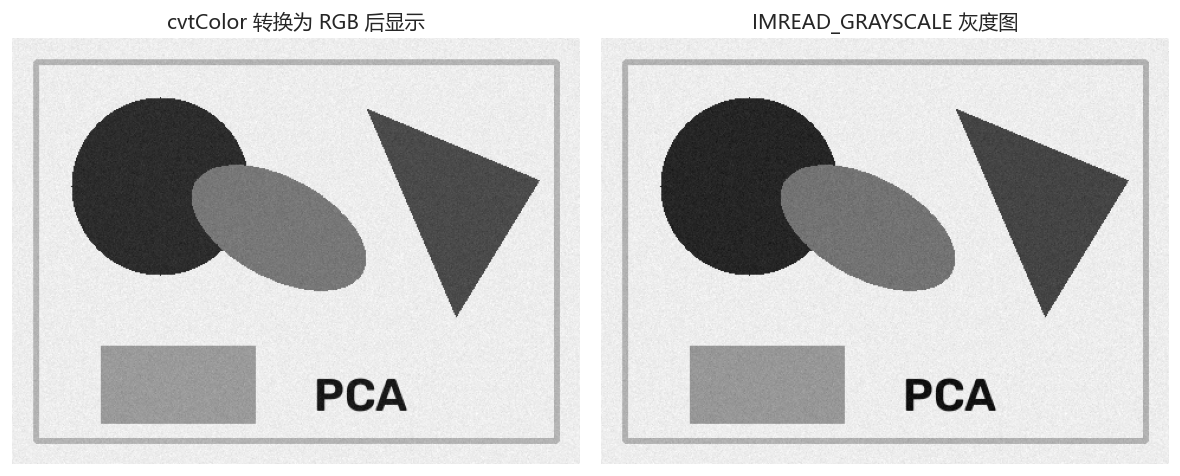

In [16]:
# 示例 3：BGR/RGB、灰度图与图像数组
color_bgr = cv2.imread(str(sample_path), cv2.IMREAD_COLOR)
color_rgb = cv2.cvtColor(color_bgr, cv2.COLOR_BGR2RGB)
direct_gray = cv2.imread(str(sample_path), cv2.IMREAD_GRAYSCALE)

print('BGR 数组:', color_bgr.shape, color_bgr.dtype)
print('RGB 数组:', color_rgb.shape, color_rgb.dtype)
print('灰度数组:', direct_gray.shape, direct_gray.dtype)
print('cvtColor 灰度与直接灰度读取一致:', np.array_equal(loaded_gray, direct_gray))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(color_rgb)
axes[0].set_title('cvtColor 转换为 RGB 后显示')
axes[0].axis('off')
axes[1].imshow(direct_gray, cmap='gray')
axes[1].set_title('IMREAD_GRAYSCALE 灰度图')
axes[1].axis('off')
plt.tight_layout()
plt.show()

## 6. 最终结论

1. 手写 PCA 与 scikit-learn `PCA` 的特征值、解释方差比例一致（主成分方向可能整体差一个符号）；
2. 鸢尾花前两个主成分累计解释了约 **97.77%** 的方差，因此二维可视化仍保留了绝大部分结构；
3. 二维图中 Setosa 与其余两类分离明显，Versicolor 与 Virginica 有局部重叠；
4. PCA 是无监督降维，标签只用于可视化检验，不参与主成分计算；
5. 协方差矩阵特征值越大，对应方向包含的方差越多；丢弃小特征值方向相当于压缩并重构数据；
6. 图像 PCA 把像素列当作特征，可以通过累计解释方差自动选择主成分数量；
7. 现代代码中应显式使用 `@` 表示矩阵乘法，协方差矩阵可优先使用 `np.linalg.eigh`，避免 `np.matrix` 语义带来的错误。

### 提交检查清单

- [x] 完整运行鸢尾花 PCA 实验；
- [x] 对加载、中心化、协方差、特征分解、排序、投影、重构和绘图补充详细注释；
- [x] 整理 NumPy、scikit-learn、Matplotlib、Seaborn、OpenCV 工具函数学习笔记与范例；
- [x] 将注释、解释和实验输出整理为 Jupyter Notebook；
- [x] 与 scikit-learn PCA 交叉验证；
- [x] 同仓库提供 HTML5 鸢尾花 PCA 交互可视化 `index.html`。

In [17]:
# 最后一组可执行断言：确保 Notebook 的结论与代码输出一致。
ratio = pca_manual.explained_variance_ratio(eigenvalues)
assert X_pca_manual.shape == (150, 2)
assert np.isclose(ratio[:2].sum(), sklearn_pca.explained_variance_ratio_.sum())
assert ratio[:2].sum() > 0.97
assert image_result_99['k'] < image_result_99['cols']
assert np.isfinite(image_result_99['reconstructed']).all()
print('全部断言通过，Notebook 可复现。')

全部断言通过，Notebook 可复现。
